In [7]:
import rebound
import airball
import numpy as np
import pal
import matplotlib.pyplot as plt

In [8]:
with np.load("data/initial_conditions.npz") as data:
    ic = {key: data[key] for key in data.files}

def setup(index):
    sim = rebound.Simulation()
    sim.G = float(ic["G"][index])
    sim.t = float(ic["t"][index])
    sim.dt = float(ic["dt"][index])

    for m, x, y, z, vx, vy, vz, r in ic["particles"][index]:
        sim.add(m=m, x=x, y=y, z=z,
                vx=vx, vy=vy, vz=vz, r=r)

    sim.N_active = int(ic["N_active"][index])
    return sim


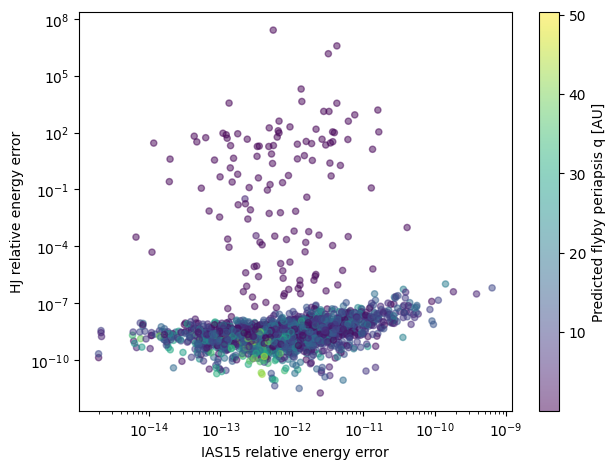

In [10]:
stars = airball.Stars("data/flyby.stars")
results = pal.unpkl("data/flyby_secular_modes.secs")
indexs = np.array([i for i, result in enumerate(results) if result.good])

indexs = np.random.default_rng().choice(indexs, size=2000, replace=False)

q = np.zeros(len(indexs))
errs = np.zeros((2, len(indexs)))
tree = [[[[[1, 2], 3], 4], 5], 6]

for i, index in enumerate(indexs):
    initial = setup(index)
    q[i] = stars[index].q(initial).to_value("AU")

    sim = initial.copy()
    res, E0 = airball.flyby(sim, stars[index], hash="flybystar")
    E1 = res.energy()
    errs[0, i] = abs((E1 - E0) / E0)
    

    sim = initial.copy()
    sim.integrator = "whfast_hj"
    sim.dt = 0.2
    res, E0 = airball.flyby(sim, stars[index], hash="flybystar", tree=tree)
    E1 = res.energy()
    errs[1, i] = abs((E1 - E0) / E0)

    np.savez(
        "flyby_errors.npz",
        indexs=indexs[:i+1],
        errs=errs[:, :i+1],
        q=q[:i+1],
    )

plt.scatter(errs[0], errs[1], c=q, cmap="viridis", s=20, alpha=0.5)
plt.colorbar(label="Predicted flyby periapsis q [AU]")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("IAS15 relative energy error")
plt.ylabel("HJ relative energy error")
plt.tight_layout()
plt.show()

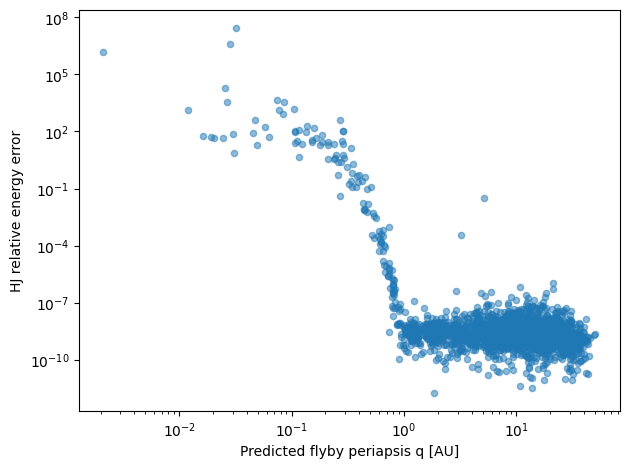

In [11]:
plt.scatter(q, errs[1], s=20, alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Predicted flyby periapsis q [AU]")
plt.ylabel("HJ relative energy error")
plt.tight_layout()
plt.show()

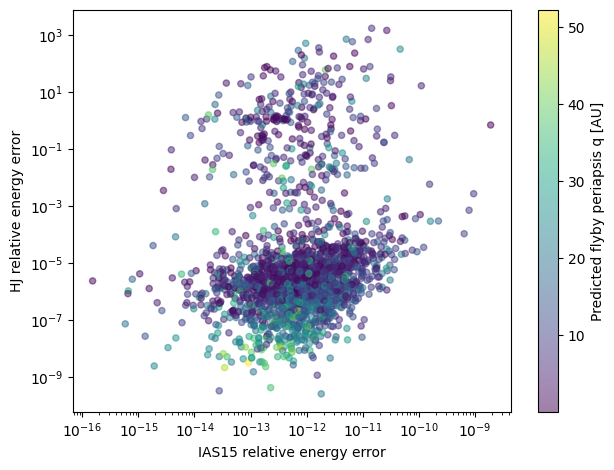

In [12]:
stars = airball.Stars("data/flyby.stars")
results = pal.unpkl("data/flyby_secular_modes.secs")
indexs = np.array([i for i, result in enumerate(results) if result.good])

indexs = np.random.default_rng().choice(indexs, size=2000, replace=False)

q = np.zeros(len(indexs))
errs = np.zeros((2, len(indexs)))
tree = [[[[[1, 6], 2], 3], 4], 5]

for i, index in enumerate(indexs):
    initial = setup(index)
    q[i] = stars[index].q(initial).to_value("AU")

    sim = initial.copy()
    res, E0 = airball.flyby(sim, stars[index], hash="flybystar")
    E1 = res.energy()
    errs[0, i] = abs((E1 - E0) / E0)
    

    sim = initial.copy()
    sim.integrator = "whfast_hj"
    sim.dt = 0.2
    res, E0 = airball.flyby(sim, stars[index], hash="flybystar", tree=tree)
    E1 = res.energy()
    errs[1, i] = abs((E1 - E0) / E0)

    np.savez(
        "flyby_errors_center.npz",
        indexs=indexs[:i+1],
        errs=errs[:, :i+1],
        q=q[:i+1],
    )

plt.scatter(errs[0], errs[1], c=q, cmap="viridis", s=20, alpha=0.5)
plt.colorbar(label="Predicted flyby periapsis q [AU]")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("IAS15 relative energy error")
plt.ylabel("HJ relative energy error")
plt.tight_layout()
plt.show()

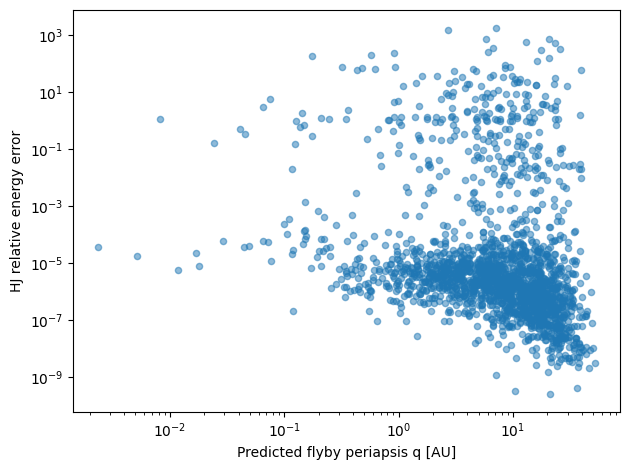

In [13]:
plt.scatter(q, errs[1], s=20, alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Predicted flyby periapsis q [AU]")
plt.ylabel("HJ relative energy error")
plt.tight_layout()
plt.show()

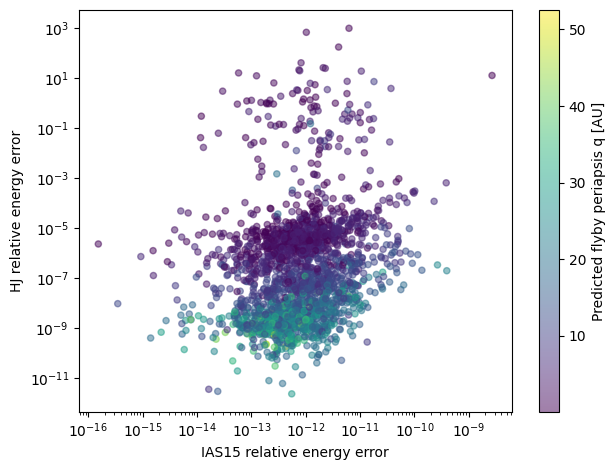

In [14]:
stars = airball.Stars("data/flyby.stars")
results = pal.unpkl("data/flyby_secular_modes.secs")
indexs = np.array([i for i, result in enumerate(results) if result.good])

indexs = np.random.default_rng().choice(indexs, size=2000, replace=False)

q = np.zeros(len(indexs))
errs = np.zeros((2, len(indexs)))

for i, index in enumerate(indexs):
    initial = setup(index)
    q[i] = stars[index].q(initial).to_value("AU")

    sim = initial.copy()
    res, E0 = airball.flyby(sim, stars[index], hash="flybystar")
    E1 = res.energy()
    errs[0, i] = abs((E1 - E0) / E0)
    

    sim = initial.copy()
    sim.integrator = "whfast_hj"
    sim.dt = 0.2

    radii = np.array([0] + [o.a for o in initial.orbits()])
    partner = int(np.argmin(np.abs(radii - q[i])))

    nodes = [1, 2, 3, 4, 5]
    nodes[partner] = [nodes[partner], 6]

    tree = nodes[0]
    for node in nodes[1:]:
        tree = [tree, node]

    res, E0 = airball.flyby(sim, stars[index], hash="flybystar", tree=tree)
    E1 = res.energy()
    errs[1, i] = abs((E1 - E0) / E0)

    np.savez(
        "flyby_errors_q_depended.npz",
        indexs=indexs[:i+1],
        errs=errs[:, :i+1],
        q=q[:i+1],
    )

plt.scatter(errs[0], errs[1], c=q, cmap="viridis", s=20, alpha=0.5)
plt.colorbar(label="Predicted flyby periapsis q [AU]")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("IAS15 relative energy error")
plt.ylabel("HJ relative energy error")
plt.tight_layout()
plt.show()

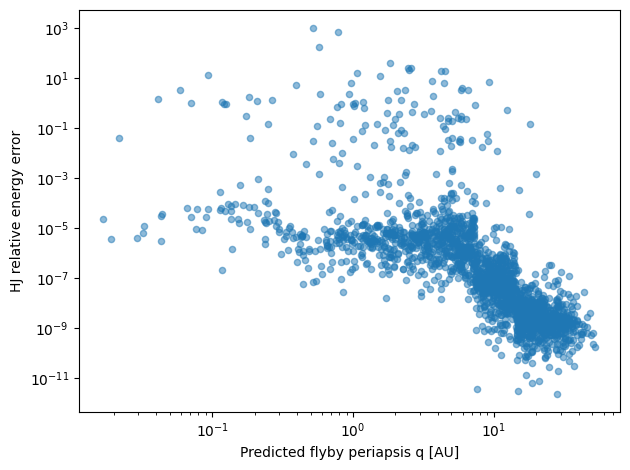

In [15]:
plt.scatter(q, errs[1], s=20, alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Predicted flyby periapsis q [AU]")
plt.ylabel("HJ relative energy error")
plt.tight_layout()
plt.show()
